In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/raw/PJME_hourly.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["Datetime"])

df = df.sort_values("Datetime").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Datetime"].min(), "to", df["Datetime"].max())
print("Missing values:\n", df.isna().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

display(df.head())

Dataset shape: (145366, 2)
Date range: 2002-01-01 01:00:00 to 2018-08-03 00:00:00
Missing values:
 Datetime    0
PJME_MW     0
dtype: int64
Duplicate timestamps: 4


,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


In [3]:
df = df.dropna(subset=["Datetime", "PJME_MW"]).copy()

df = (
    df.sort_values("Datetime")
      .drop_duplicates(subset=["Datetime"])
      .reset_index(drop=True)
)

time_diffs = df["Datetime"].diff()

print("Time gap counts:")
display(time_diffs.value_counts().head(10))

expected_gap = pd.Timedelta(hours=1)

print("Non-hourly gaps:", (time_diffs.dropna() != expected_gap).sum())
print("Missing hourly timestamps:", int(
    (time_diffs.dropna() / expected_gap - 1)
    .clip(lower=0)
    .sum()
))

Time gap counts:


Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
Name: count, dtype: int64

Non-hourly gaps: 30
Missing hourly timestamps: 30


In [4]:
expected_timestamps = pd.date_range(
    start=df["Datetime"].min(),
    end=df["Datetime"].max(),
    freq="h"
)

missing_timestamps = expected_timestamps.difference(
    pd.DatetimeIndex(df["Datetime"])
)

print("Missing timestamps:", len(missing_timestamps))
display(pd.DataFrame({"Missing_Datetime": missing_timestamps}))

Missing timestamps: 30


,Missing_Datetime
0,2002-04-07 03:00:00
1,2002-10-27 02:00:00
2,2003-04-06 03:00:00
3,2003-10-26 02:00:00
4,2004-04-04 03:00:00
5,2004-10-31 02:00:00
6,2005-04-03 03:00:00
7,2005-10-30 02:00:00
8,2006-04-02 03:00:00
9,2006-10-29 02:00:00


In [5]:
for missing_time in missing_timestamps:
    nearby = df[
        df["Datetime"].between(
            missing_time - pd.Timedelta(hours=2),
            missing_time + pd.Timedelta(hours=2)
        )
    ][["Datetime", "PJME_MW"]]

    print(f"\nMissing timestamp: {missing_time}")
    display(nearby)


Missing timestamp: 2002-04-07 03:00:00


,Datetime,PJME_MW
2304,2002-04-07 01:00:00,25608.0
2305,2002-04-07 02:00:00,24738.0
2306,2002-04-07 04:00:00,24487.0
2307,2002-04-07 05:00:00,24617.0



Missing timestamp: 2002-10-27 02:00:00


,Datetime,PJME_MW
7174,2002-10-27 00:00:00,24387.0
7175,2002-10-27 01:00:00,22823.0
7176,2002-10-27 03:00:00,20605.0
7177,2002-10-27 04:00:00,20534.0



Missing timestamp: 2003-04-06 03:00:00


...

,Datetime,PJME_MW
124413,2016-03-13 01:00:00,22003.0
124414,2016-03-13 02:00:00,21292.0
124415,2016-03-13 04:00:00,20816.0
124416,2016-03-13 05:00:00,20704.0



Missing timestamp: 2017-03-12 03:00:00


,Datetime,PJME_MW
133148,2017-03-12 01:00:00,30935.0
133149,2017-03-12 02:00:00,30384.0
133150,2017-03-12 04:00:00,29985.0
133151,2017-03-12 05:00:00,30109.0



Missing timestamp: 2018-03-11 03:00:00


,Datetime,PJME_MW
141883,2018-03-11 01:00:00,27517.0
141884,2018-03-11 02:00:00,27012.0
141885,2018-03-11 04:00:00,26866.0
141886,2018-03-11 05:00:00,27061.0


In [6]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/raw/PJME_hourly.csv")

raw_df = pd.read_csv(DATA_PATH, parse_dates=["Datetime"])

print("Original row count:", len(raw_df))
print(
    "Duplicate timestamps in original CSV:",
    raw_df["Datetime"].duplicated().sum()
)

check_time = pd.Timestamp("2010-12-10 00:00:00")

nearby = raw_df[
    raw_df["Datetime"].between(
        check_time - pd.Timedelta(hours=4),
        check_time + pd.Timedelta(hours=4)
    )
][["Datetime", "PJME_MW"]]

display(nearby)

Original row count: 145366
Duplicate timestamps in original CSV: 4


,Datetime,PJME_MW
70616,2010-12-10 01:00:00,33163.0
70617,2010-12-10 02:00:00,32323.0
70618,2010-12-10 03:00:00,32016.0
70619,2010-12-10 04:00:00,32008.0
70659,2010-12-09 20:00:00,42411.0
70660,2010-12-09 21:00:00,41851.0
70661,2010-12-09 22:00:00,40288.0
70662,2010-12-09 23:00:00,37729.0


In [7]:
# Find every row whose timestamp is duplicated
duplicate_rows = raw_df[
    raw_df["Datetime"].duplicated(keep=False)
].sort_values("Datetime")

display(duplicate_rows)

print("Total rows involved in duplicate timestamps:", len(duplicate_rows))
print(
    "Number of distinct duplicated timestamps:",
    duplicate_rows["Datetime"].nunique()
)

# Check whether duplicate timestamps have identical demand values
duplicate_summary = (
    duplicate_rows.groupby("Datetime")
    .agg(
        Row_Count=("PJME_MW", "size"),
        Unique_Demand_Values=("PJME_MW", "nunique"),
        Demand_Values=("PJME_MW", lambda x: list(x))
    )
    .reset_index()
)

display(duplicate_summary)

,Datetime,PJME_MW
106584,2014-11-02 02:00:00,22935.0
106585,2014-11-02 02:00:00,23755.0
115368,2015-11-01 02:00:00,21567.0
115369,2015-11-01 02:00:00,21171.0
124008,2016-11-06 02:00:00,20795.0
124009,2016-11-06 02:00:00,21692.0
132816,2017-11-05 02:00:00,21236.0
132817,2017-11-05 02:00:00,20666.0


Total rows involved in duplicate timestamps: 8
Number of distinct duplicated timestamps: 4


,Datetime,Row_Count,Unique_Demand_Values,Demand_Values
0,2014-11-02 02:00:00,2,2,"[22935.0, 23755.0]"
1,2015-11-01 02:00:00,2,2,"[21567.0, 21171.0]"
2,2016-11-06 02:00:00,2,2,"[20795.0, 21692.0]"
3,2017-11-05 02:00:00,2,2,"[21236.0, 20666.0]"


In [8]:
# Check the original sequence around the repeated autumn hours
for date in [
    "2014-11-02",
    "2015-11-01",
    "2016-11-06",
    "2017-11-05",
]:
    print(f"\n--- {date} ---")

    day_data = raw_df[
        raw_df["Datetime"].between(
            pd.Timestamp(date),
            pd.Timestamp(date) + pd.Timedelta(days=1)
        )
    ][["Datetime", "PJME_MW"]]

    display(day_data.head(7))
    display(day_data.tail(5))


--- 2014-11-02 ---


,Datetime,PJME_MW
106583,2014-11-02 01:00:00,23538.0
106584,2014-11-02 02:00:00,22935.0
106585,2014-11-02 02:00:00,23755.0
106586,2014-11-02 03:00:00,22789.0
106587,2014-11-02 04:00:00,22555.0
106588,2014-11-02 05:00:00,23247.0
106589,2014-11-02 06:00:00,23733.0


,Datetime,PJME_MW
106604,2014-11-02 21:00:00,30860.0
106605,2014-11-02 22:00:00,29397.0
106606,2014-11-02 23:00:00,27690.0
106607,2014-11-03 00:00:00,25218.0
106631,2014-11-02 00:00:00,25838.0



--- 2015-11-01 ---


,Datetime,PJME_MW
115367,2015-11-01 01:00:00,22614.0
115368,2015-11-01 02:00:00,21567.0
115369,2015-11-01 02:00:00,21171.0
115370,2015-11-01 03:00:00,20861.0
115371,2015-11-01 04:00:00,20624.0
115372,2015-11-01 05:00:00,21047.0
115373,2015-11-01 06:00:00,21382.0


...

,Datetime,PJME_MW
124007,2016-11-06 01:00:00,22259.0
124008,2016-11-06 02:00:00,20795.0
124009,2016-11-06 02:00:00,21692.0
124010,2016-11-06 03:00:00,20609.0
124011,2016-11-06 04:00:00,20623.0
124012,2016-11-06 05:00:00,20805.0
124013,2016-11-06 06:00:00,21480.0


,Datetime,PJME_MW
124028,2016-11-06 21:00:00,27712.0
124029,2016-11-06 22:00:00,26426.0
124030,2016-11-06 23:00:00,24805.0
124031,2016-11-07 00:00:00,23412.0
124055,2016-11-06 00:00:00,23533.0



--- 2017-11-05 ---


,Datetime,PJME_MW
132815,2017-11-05 01:00:00,22166.0
132816,2017-11-05 02:00:00,21236.0
132817,2017-11-05 02:00:00,20666.0
132818,2017-11-05 03:00:00,20409.0
132819,2017-11-05 04:00:00,20240.0
132820,2017-11-05 05:00:00,20356.0
132821,2017-11-05 06:00:00,20947.0


,Datetime,PJME_MW
132836,2017-11-05 21:00:00,27448.0
132837,2017-11-05 22:00:00,25983.0
132838,2017-11-05 23:00:00,24187.0
132839,2017-11-06 00:00:00,22597.0
132863,2017-11-05 00:00:00,23493.0


In [9]:
# Inspect original row order around the 2014 DST transition
start_idx = 106578
end_idx = 106592

display(
    raw_df.iloc[start_idx:end_idx][["Datetime", "PJME_MW"]]
)

# Check whether timestamps are non-decreasing in the original CSV
is_ordered = raw_df["Datetime"].is_monotonic_increasing
print("Original timestamps non-decreasing:", is_ordered)

# Show any rows where timestamps move backwards
backward_steps = raw_df.loc[
    raw_df["Datetime"].diff() < pd.Timedelta(0),
    ["Datetime", "PJME_MW"]
]

print("Backward timestamp steps:", len(backward_steps))
display(backward_steps.head(10))

,Datetime,PJME_MW
106578,2014-11-03 20:00:00,32770.0
106579,2014-11-03 21:00:00,31734.0
106580,2014-11-03 22:00:00,29935.0
106581,2014-11-03 23:00:00,27657.0
106582,2014-11-04 00:00:00,25583.0
106583,2014-11-02 01:00:00,23538.0
106584,2014-11-02 02:00:00,22935.0
106585,2014-11-02 02:00:00,23755.0
106586,2014-11-02 03:00:00,22789.0
106587,2014-11-02 04:00:00,22555.0


Original timestamps non-decreasing: False
Backward timestamp steps: 6041


,Datetime,PJME_MW
24,2002-12-30 01:00:00,27526.0
48,2002-12-29 01:00:00,27084.0
72,2002-12-28 01:00:00,29344.0
96,2002-12-27 01:00:00,28445.0
120,2002-12-26 01:00:00,26705.0
144,2002-12-25 01:00:00,27669.0
168,2002-12-24 01:00:00,27213.0
192,2002-12-23 01:00:00,25460.0
216,2002-12-22 01:00:00,27142.0
240,2002-12-21 01:00:00,26969.0


In [10]:
# Check the overall ordering of the original dataset
print("First 10 rows:")
display(raw_df[["Datetime", "PJME_MW"]].head(10))

print("Last 10 rows:")
display(raw_df[["Datetime", "PJME_MW"]].tail(10))

print("First and last timestamps:")
print("First:", raw_df["Datetime"].iloc[0])
print("Last:", raw_df["Datetime"].iloc[-1])

# Inspect duplicate timestamps in their original row order
duplicate_mask = raw_df["Datetime"].duplicated(keep=False)

duplicates_original_order = (
    raw_df.loc[duplicate_mask, ["Datetime", "PJME_MW"]]
    .sort_values("Datetime", kind="stable")
)

display(duplicates_original_order)

First 10 rows:


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0
5,2002-12-31 06:00:00,26222.0
6,2002-12-31 07:00:00,28702.0
7,2002-12-31 08:00:00,30698.0
8,2002-12-31 09:00:00,31800.0
9,2002-12-31 10:00:00,32359.0


Last 10 rows:


,Datetime,PJME_MW
145356,2018-01-01 15:00:00,38737.0
145357,2018-01-01 16:00:00,39337.0
145358,2018-01-01 17:00:00,41213.0
145359,2018-01-01 18:00:00,44147.0
145360,2018-01-01 19:00:00,44343.0
145361,2018-01-01 20:00:00,44284.0
145362,2018-01-01 21:00:00,43751.0
145363,2018-01-01 22:00:00,42402.0
145364,2018-01-01 23:00:00,40164.0
145365,2018-01-02 00:00:00,38608.0


First and last timestamps:
First: 2002-12-31 01:00:00
Last: 2018-01-02 00:00:00


,Datetime,PJME_MW
106584,2014-11-02 02:00:00,22935.0
106585,2014-11-02 02:00:00,23755.0
115368,2015-11-01 02:00:00,21567.0
115369,2015-11-01 02:00:00,21171.0
124008,2016-11-06 02:00:00,20795.0
124009,2016-11-06 02:00:00,21692.0
132816,2017-11-05 02:00:00,21236.0
132817,2017-11-05 02:00:00,20666.0


In [11]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/raw/PJME_hourly.csv")

raw_df = pd.read_csv(DATA_PATH, parse_dates=["Datetime"])

# Remove only rows with missing timestamp or target
df = raw_df.dropna(subset=["Datetime", "PJME_MW"]).copy()

# Sort chronologically; preserve both repeated-hour observations
df = df.sort_values("Datetime", kind="stable").reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Chronological order:", df["Datetime"].is_monotonic_increasing)
print("Duplicate timestamps preserved:", df["Datetime"].duplicated().sum())

display(df.head())
display(df.loc[df["Datetime"].duplicated(keep=False), ["Datetime", "PJME_MW"]])

Rows after cleaning: 145366
Chronological order: True
Duplicate timestamps preserved: 4


,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


,Datetime,PJME_MW
112487,2014-11-02 02:00:00,22935.0
112488,2014-11-02 02:00:00,23755.0
121223,2015-11-01 02:00:00,21567.0
121224,2015-11-01 02:00:00,21171.0
130127,2016-11-06 02:00:00,20795.0
130128,2016-11-06 02:00:00,21692.0
138863,2017-11-05 02:00:00,21236.0
138864,2017-11-05 02:00:00,20666.0


In [12]:
# Calculate time difference between consecutive observations
time_diff = df["Datetime"].diff()

print("Time difference counts:")
display(time_diff.value_counts().head(10))

# Identify gaps larger than one hour
gaps = df.loc[
    time_diff > pd.Timedelta(hours=1),
    ["Datetime", "PJME_MW"]
].copy()

gaps["Previous_Datetime"] = df["Datetime"].shift(1).loc[gaps.index]
gaps["Gap"] = (
    gaps["Datetime"] - gaps["Previous_Datetime"]
)

print("Gaps larger than one hour:", len(gaps))
display(gaps.head(40))

# Inspect repeated-hour observations
duplicate_rows = df[
    df["Datetime"].duplicated(keep=False)
].copy()

print("Repeated-hour observations:")
display(duplicate_rows)

Time difference counts:


Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64

Gaps larger than one hour: 30


,Datetime,PJME_MW,Previous_Datetime,Gap
2306,2002-04-07 04:00:00,24487.0,2002-04-07 02:00:00,0 days 02:00:00
7176,2002-10-27 03:00:00,20605.0,2002-10-27 01:00:00,0 days 02:00:00
11040,2003-04-06 04:00:00,22902.0,2003-04-06 02:00:00,0 days 02:00:00
15910,2003-10-26 03:00:00,20641.0,2003-10-26 01:00:00,0 days 02:00:00
19774,2004-04-04 04:00:00,23208.0,2004-04-04 02:00:00,0 days 02:00:00
24812,2004-10-31 03:00:00,20585.0,2004-10-31 01:00:00,0 days 02:00:00
28508,2005-04-03 04:00:00,23414.0,2005-04-03 02:00:00,0 days 02:00:00
33546,2005-10-30 03:00:00,23302.0,2005-10-30 01:00:00,0 days 02:00:00
37242,2006-04-02 04:00:00,20833.0,2006-04-02 02:00:00,0 days 02:00:00
42280,2006-10-29 03:00:00,23310.0,2006-10-29 01:00:00,0 days 02:00:00


Repeated-hour observations:


,Datetime,PJME_MW
112487,2014-11-02 02:00:00,22935.0
112488,2014-11-02 02:00:00,23755.0
121223,2015-11-01 02:00:00,21567.0
121224,2015-11-01 02:00:00,21171.0
130127,2016-11-06 02:00:00,20795.0
130128,2016-11-06 02:00:00,21692.0
138863,2017-11-05 02:00:00,21236.0
138864,2017-11-05 02:00:00,20666.0


In [13]:
# Inspect observations around the unusual December 2010 gap
gap_time = pd.Timestamp("2010-12-10 00:00:00")

window = df[
    (df["Datetime"] >= gap_time - pd.Timedelta(hours=5))
    & (df["Datetime"] <= gap_time + pd.Timedelta(hours=5))
][["Datetime", "PJME_MW"]]

display(window)

# Confirm the exact timestamp gap
position = df.index[df["Datetime"] == gap_time]

if len(position) > 0:
    i = position[0]
    print("Previous observation:", df.loc[i - 1, "Datetime"])
    print("Current observation:", df.loc[i, "Datetime"])
    print("Gap:", df.loc[i, "Datetime"] - df.loc[i - 1, "Datetime"])

,Datetime,PJME_MW
78336,2010-12-09 19:00:00,42744.0
78337,2010-12-09 20:00:00,42411.0
78338,2010-12-09 21:00:00,41851.0
78339,2010-12-09 22:00:00,40288.0
78340,2010-12-09 23:00:00,37729.0
78341,2010-12-10 01:00:00,33163.0
78342,2010-12-10 02:00:00,32323.0
78343,2010-12-10 03:00:00,32016.0
78344,2010-12-10 04:00:00,32008.0
78345,2010-12-10 05:00:00,32665.0


In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Keep repeated timestamps; sort chronologically
df = df.sort_values("Datetime", kind="stable").reset_index(drop=True)

# Baselines use previous observations only
df["Persistence_Prediction"] = df["PJME_MW"].shift(1)
df["Seasonal_Naive_Prediction"] = df["PJME_MW"].shift(24)

# Chronological split — no random shuffle
split_idx = int(len(df) * 0.80)

test = df.iloc[split_idx:].copy()

# Exclude rows where baseline predictions are unavailable
test = test.dropna(
    subset=[
        "PJME_MW",
        "Persistence_Prediction",
        "Seasonal_Naive_Prediction",
    ]
)

print("Total observations:", len(df))
print("Train cutoff:", df.loc[split_idx - 1, "Datetime"])
print("Test start:", test["Datetime"].iloc[0])
print("Test observations:", len(test))
display(test.head())

Total observations: 145366
Train cutoff: 2015-04-09 14:00:00
Test start: 2015-04-09 15:00:00
Test observations: 29074


,Datetime,PJME_MW,Persistence_Prediction,Seasonal_Naive_Prediction
116292,2015-04-09 15:00:00,32204.0,32613.0,31549.0
116293,2015-04-09 16:00:00,32049.0,32204.0,31457.0
116294,2015-04-09 17:00:00,32209.0,32049.0,31767.0
116295,2015-04-09 18:00:00,32707.0,32209.0,32338.0
116296,2015-04-09 19:00:00,33012.0,32707.0,32733.0


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_results = []

for model_name, prediction_col in [
    ("Persistence", "Persistence_Prediction"),
    ("Seasonal Naive (24 rows)", "Seasonal_Naive_Prediction"),
]:
    actual = test["PJME_MW"]
    predicted = test[prediction_col]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    baseline_results.append({
        "Model": model_name,
        "MAE_MW": round(mae, 2),
        "RMSE_MW": round(rmse, 2),
    })

baseline_metrics = pd.DataFrame(baseline_results)
display(baseline_metrics)

,Model,MAE_MW,RMSE_MW
0,Persistence,1069.76,1373.61
1,Seasonal Naive (24 rows),2183.07,3007.91


In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

RESULTS_PATH = Path("../data/processed/forecast_test_results_v2.csv")

rf_results = pd.read_csv(RESULTS_PATH, parse_dates=["Datetime"])
rf_results = rf_results.sort_values("Datetime").reset_index(drop=True)

print("Saved RF rows:", len(rf_results))
print("Saved RF date range:",
      rf_results["Datetime"].min(), "to", rf_results["Datetime"].max())

print("\nCurrent test date range:",
      test["Datetime"].min(), "to", test["Datetime"].max())

display(rf_results.head())

Saved RF rows: 29039
Saved RF date range: 2015-04-10 23:00:00 to 2018-08-03 00:00:00

Current test date range: 2015-04-09 15:00:00 to 2018-08-03 00:00:00


,Datetime,PJME_MW,Forecast,Baseline_Prediction
0,2015-04-10 23:00:00,27327.0,27153.967070,29187.0
1,2015-04-11 00:00:00,25390.0,25082.833318,27327.0
2,2015-04-11 01:00:00,23728.0,23545.637144,25390.0
3,2015-04-11 02:00:00,22743.0,22486.595219,23728.0
4,2015-04-11 03:00:00,22276.0,21971.834294,22743.0


In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model_df = df.copy()

# Calendar features
model_df["Hour"] = model_df["Datetime"].dt.hour
model_df["DayOfWeek"] = model_df["Datetime"].dt.dayofweek
model_df["Month"] = model_df["Datetime"].dt.month
model_df["IsWeekend"] = (
    model_df["DayOfWeek"] >= 5
).astype(int)

# Lag features: past observations only
model_df["Lag_1"] = model_df["PJME_MW"].shift(1)
model_df["Lag_24"] = model_df["PJME_MW"].shift(24)
model_df["Lag_168"] = model_df["PJME_MW"].shift(168)

# Shift rolling means so current target is not included
model_df["Rolling_Mean_24"] = (
    model_df["PJME_MW"].shift(1).rolling(24).mean()
)
model_df["Rolling_Mean_168"] = (
    model_df["PJME_MW"].shift(1).rolling(168).mean()
)

feature_cols = [
    "Hour", "DayOfWeek", "Month", "IsWeekend",
    "Lag_1", "Lag_24", "Lag_168",
    "Rolling_Mean_24", "Rolling_Mean_168"
]

# Use the same original chronological cutoff
split_idx = int(len(df) * 0.80)

train_df = model_df.iloc[:split_idx].dropna(
    subset=feature_cols + ["PJME_MW"]
)
test_df = model_df.iloc[split_idx:].dropna(
    subset=feature_cols + ["PJME_MW"]
)

X_train = train_df[feature_cols]
y_train = train_df["PJME_MW"]

X_test = test_df[feature_cols]
y_test = test_df["PJME_MW"]

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Test start:", test_df["Datetime"].min())
print("Test end:", test_df["Datetime"].max())
print(f"Random Forest MAE: {rf_mae:.2f} MW")
print(f"Random Forest RMSE: {rf_rmse:.2f} MW")

Train rows: 116124
Test rows: 29074
Test start: 2015-04-09 15:00:00
Test end: 2018-08-03 00:00:00
Random Forest MAE: 331.58 MW
Random Forest RMSE: 458.80 MW


,Model,MAE_MW,RMSE_MW
0,Persistence,1069.76,1373.61
1,Seasonal_Naive,2183.07,3007.91
2,Random_Forest,331.58,458.80


<module 'matplotlib.pyplot' from 'c:\\Users\\ASUS\\GridSense\\.venv\\Lib\\site-packages\\matplotlib\\pyplot.py'>

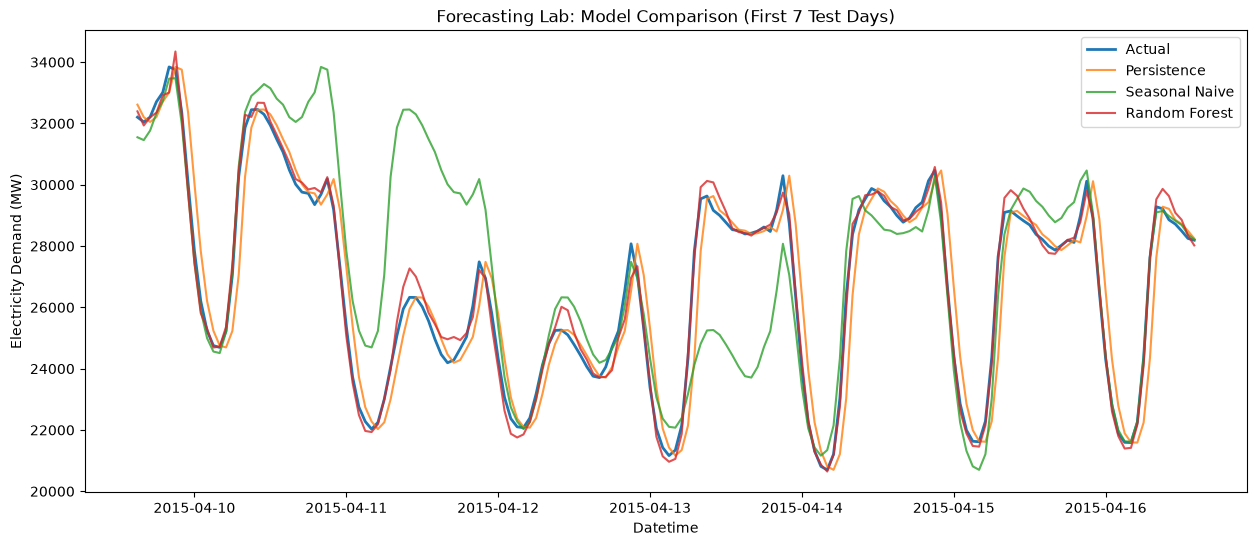

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Align all predictions to exactly the same test rows
comparison = test_df[
    ["Datetime", "PJME_MW"]
].copy()

comparison["Persistence"] = test_df["PJME_MW"].shift(1).values
comparison["Seasonal_Naive"] = test_df["PJME_MW"].shift(24).values

# For test-set baselines, use lag values from the complete timeline
comparison["Persistence"] = model_df.loc[
    test_df.index, "Persistence_Prediction"
].values

comparison["Seasonal_Naive"] = model_df.loc[
    test_df.index, "Seasonal_Naive_Prediction"
].values

comparison["Random_Forest"] = rf_pred

# Calculate metrics on common rows
metric_rows = []

for model_name in ["Persistence", "Seasonal_Naive", "Random_Forest"]:
    valid = comparison[["PJME_MW", model_name]].dropna()

    metric_rows.append({
        "Model": model_name,
        "MAE_MW": mean_absolute_error(
            valid["PJME_MW"], valid[model_name]
        ),
        "RMSE_MW": np.sqrt(mean_squared_error(
            valid["PJME_MW"], valid[model_name]
        )),
    })

comparison_metrics = pd.DataFrame(metric_rows).round(2)
display(comparison_metrics)

# Plot a sample of 7 days to avoid an overcrowded chart
sample = comparison.iloc[:168]

plt.figure(figsize=(15, 6))
plt.plot(sample["Datetime"], sample["PJME_MW"], label="Actual", linewidth=2)
plt.plot(sample["Datetime"], sample["Persistence"], label="Persistence", alpha=0.8)
plt.plot(sample["Datetime"], sample["Seasonal_Naive"], label="Seasonal Naive", alpha=0.8)
plt.plot(sample["Datetime"], sample["Random_Forest"], label="Random Forest", alpha=0.8)

plt.title("Forecasting Lab: Model Comparison (First 7 Test Days)")
plt.xlabel("Datetime")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt

In [19]:
# Check that all models have predictions for exactly the same rows
cols = [
    "PJME_MW",
    "Persistence",
    "Seasonal_Naive",
    "Random_Forest",
]

print("Total comparison rows:", len(comparison))
print("Rows with all predictions:", comparison[cols].dropna().shape[0])
print("Missing values per column:")
display(comparison[cols].isna().sum())

# Recalculate metrics using only common rows
common = comparison[cols].dropna()

for model_name in ["Persistence", "Seasonal_Naive", "Random_Forest"]:
    mae = mean_absolute_error(common["PJME_MW"], common[model_name])
    rmse = np.sqrt(mean_squared_error(common["PJME_MW"], common[model_name]))
    print(f"{model_name}: MAE={mae:.2f} MW | RMSE={rmse:.2f} MW")

Total comparison rows: 29074
Rows with all predictions: 29074
Missing values per column:


PJME_MW           0
Persistence       0
Seasonal_Naive    0
Random_Forest     0
dtype: int64

Persistence: MAE=1069.76 MW | RMSE=1373.61 MW
Seasonal_Naive: MAE=2183.07 MW | RMSE=3007.91 MW
Random_Forest: MAE=331.58 MW | RMSE=458.80 MW


In [21]:
from pathlib import Path

# Create output folders
reports_dir = Path("../reports")
processed_dir = Path("../data/processed")

reports_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison metrics
metrics_path = reports_dir / "forecasting_model_comparison.csv"
comparison_metrics.to_csv(metrics_path, index=False)

# Save aligned actual values and predictions
predictions_path = processed_dir / "forecasting_lab_predictions.csv"
comparison.to_csv(predictions_path, index=False)

# Confirm exact paths and file sizes
for path in [metrics_path, predictions_path]:
    print("Saved:", path.resolve())
    print("Exists:", path.exists())
    print("Size:", path.stat().st_size, "bytes")
    print()

Saved: C:\Users\ASUS\GridSense\reports\forecasting_model_comparison.csv
Exists: True
Size: 111 bytes

Saved: C:\Users\ASUS\GridSense\data\processed\forecasting_lab_predictions.csv
Exists: True
Size: 1844979 bytes

